# Step 14 — pregnant women: general model against a model trained on pregnant women only

The analysis population leaves out women who are pregnant at the examination (`nhanes.cohort.population`). This notebook looks at them as a specific group: how well does the model trained on everyone else predict PHQ-9 ≥ 10 in pregnant women, and does a model trained on pregnant women only do better?

**Pregnant cohort:** age ≥ 20, pregnant at exam (`RIDEXPRG == 1`), all nine PHQ-9 items answered: 630 women, 51 with PHQ-9 ≥ 10 (8.1%), ages 20–44. Half of them (309, 23 positive) are in 2005–06, the last cycle in which NHANES oversampled pregnant women; the later cycles have 45–59 women and 2–8 positives each.

**Features:** the same 317 features, built by the same pipeline: `NHANES_COHORT=pregnant` with `pipeline/build_features.ipynb` writes `$NHANES_WORK/features_pregnant/` with the columns of the main table. NHANES has no public gestational age or prenatal-care variables in these cycles, so nothing specific to the pregnancy is added.

**Models, all leave-one-cycle-out (LOCO):** for each test cycle, train on the other 6 cycles and predict the pregnant women of the test cycle.

| name | training rows (other 6 cycles) | hyper-parameters |
|---|---|---|
| general | the analysis population, no pregnant women: the step 1 model | step 1's choice for that test cycle (reproduces step 1) |
| general + pregnant | the same plus the pregnant women of the training cycles | step 1's choice, not retuned |
| pregnant only | pregnant women only (about 320 to 585, 28 to 49 positive) | inner LOCO over the training cycles, as in step 1 |

Elastic net and XGBoost for each.

**Evaluation.** A single test cycle after 2005–06 has 2–8 positives, so AUROC per cycle is not usable and the step 1 headline (mean over cycles) is not reported. Instead, over the 630 out-of-cycle predictions:
- **Pooled AUROC** with a 95% bootstrap interval (2,000 resamples of women).
- **Within-cycle AUROC:** positive–negative pairs are only compared inside the same test cycle and the cycles are weighted by their number of pairs. Each LOCO fold is a different model, and with a few hundred training rows the pregnant-only models can differ in the level of their scores from fold to fold; the pooled AUROC is penalised by that, the within-cycle AUROC is not.
- **Difference between models** on the same women, with a paired bootstrap interval.

**Reference:** the general model on non-pregnant women aged 20–44 (step 1 predictions; 6,733 women, 10.9% positive). This separates "pregnant" from "young women".

**Output:** `$NHANES_WORK/modeling/step14_pregnant/` with `predictions.csv.gz`, `metrics.csv`, `pregnant_only/` (the `run_loco` files). `RUN = True` retrains (about 15 minutes on 4 threads, CPU only); `RUN = False` only reads the saved results.

In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import roc_auc_score

_cwd = Path.cwd().resolve()
ROOT = next((p for p in [_cwd, *_cwd.parents] if (p / "nhanes" / "paths.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("run this notebook from inside the repository")
sys.path.insert(0, str(ROOT))
from nhanes import plots  # noqa: E402
from nhanes.paths import RESULTS, WORK  # noqa: E402

RUN = False  # True: retrain and overwrite $NHANES_WORK/modeling/step14_pregnant
RUN = RUN or os.environ.get("NHANES_RUN") == "1"
OUT = RESULTS / "step14_pregnant"
STEP1 = RESULTS / "step1"
NAMES = {"logreg": "elastic net", "xgboost": "XGBoost"}
TRAININGS = ["general", "general + pregnant", "pregnant only"]

## Run

In [2]:
if RUN:
    from nhanes.loco import FEAT, NOT_FEATURES, fit_logreg, fit_xgb, logreg_matrix, run_loco

    OUT.mkdir(parents=True, exist_ok=True)
    main = pd.read_csv(FEAT / "features_2005_2018.csv.gz")
    preg = pd.read_csv(WORK / "features_pregnant" / "features_2005_2018.csv.gz")
    assert list(preg.columns) == list(main.columns) and not set(preg.SEQN) & set(main.SEQN)
    dic = pd.read_csv(FEAT / "feature_dictionary.csv").set_index("column").type.to_dict()
    feats = [c for c in main if c not in NOT_FEATURES]
    chosen = json.loads((STEP1 / "chosen_params.json").read_text())
    cycles = sorted(main.cycle.unique())

    preds = []
    for c in cycles:
        te = preg[preg.cycle == c]
        for training, tr in [("general", main[main.cycle != c]),
                             ("general + pregnant", pd.concat([main[main.cycle != c], preg[preg.cycle != c]]))]:
            for model in NAMES:
                p = {k: v for k, v in chosen[f"{model}|{c}"].items() if k != "inner_auroc"}
                if model == "logreg":
                    A, B = logreg_matrix(tr[feats], te[feats], dic)
                    prob = fit_logreg(A, tr.depression, p).predict_proba(B)[:, 1]
                else:
                    n = p.pop("n_estimators")
                    prob = fit_xgb(tr[feats], tr.depression, None, None, p, n_estimators=n).predict_proba(te[feats])[:, 1]
                preds.append(pd.DataFrame({"SEQN": te.SEQN, "cycle": c, "training": training, "model": model,
                                           "depression": te.depression, "prob": prob}))
        print(c, "general models done", flush=True)

    run_loco(preg, dic, OUT / "pregnant_only", title="LOCO within pregnant women only, 317 features")
    own = pd.read_csv(OUT / "pregnant_only" / "predictions.csv.gz").assign(training="pregnant only")
    preds.append(own[["SEQN", "cycle", "training", "model", "depression", "prob"]])
    pd.concat(preds, ignore_index=True).to_csv(OUT / "predictions.csv.gz", index=False)

    ref = pd.read_csv(STEP1 / "predictions.csv.gz").merge(main[["SEQN", "RIAGENDR", "RIDAGEYR"]], on="SEQN")
    ref = ref[(ref.RIAGENDR == 2) & ref.RIDAGEYR.between(20, 44)]
    ref[["SEQN", "cycle", "model", "depression", "prob"]].to_csv(OUT / "reference_women_20_44.csv.gz", index=False)

## The cohort

In [3]:
pred = pd.read_csv(OUT / "predictions.csv.gz")
ref = pd.read_csv(OUT / "reference_women_20_44.csv.gz")
one = pred[(pred.training == "general") & (pred.model == "logreg")]
cohort = pd.DataFrame({"pregnant women": one.groupby("cycle").size(),
                       "PHQ-9 ≥ 10": one.groupby("cycle").depression.sum(),
                       "non-pregnant women 20–44": ref[ref.model == "logreg"].groupby("cycle").size(),
                       "PHQ-9 ≥ 10 ": ref[ref.model == "logreg"].groupby("cycle").depression.sum()})
cohort.loc["total"] = cohort.sum()
display(cohort)

,pregnant women,PHQ-9 ≥ 10,non-pregnant women 20–44,PHQ-9 ≥ 10
cycle,,,,
2005-06,309,23,810,55
2007-08,53,4,996,145
2009-10,59,7,1085,135
2011-12,45,2,889,94
2013-14,59,8,1044,110
2015-16,59,5,993,95
2017-18,46,2,916,97
total,630,51,6733,731


## Results

In [4]:
def within_cycle_auc(y, p, cycle):
    """AUROC over positive-negative pairs from the same cycle (cycles weighted by their number of pairs)."""
    num = den = 0.0
    for c in np.unique(cycle):
        m = cycle == c
        pairs = y[m].sum() * (1 - y[m]).sum()
        if pairs:
            num += roc_auc_score(y[m], p[m]) * pairs
            den += pairs
    return num / den


def boot(frames, stat, n=2000, seed=42):
    """Bootstrap over people; `frames` are aligned on the same people. Returns an array n x len(frames)."""
    rng = np.random.default_rng(seed)
    size = len(frames[0])
    out = []
    while len(out) < n:
        i = rng.integers(0, size, size)
        if frames[0].depression.to_numpy()[i].min() == frames[0].depression.to_numpy()[i].max():
            continue
        out.append([stat(f.depression.to_numpy()[i], f.prob.to_numpy()[i], f.cycle.to_numpy()[i]) for f in frames])
    return np.array(out)


pooled = lambda y, p, c: roc_auc_score(y, p)  # noqa: E731
rows = []
for model in NAMES:
    sets = {t: pred[(pred.training == t) & (pred.model == model)].sort_values("SEQN") for t in TRAININGS}
    frames = list(sets.values())
    assert all((f.SEQN.to_numpy() == frames[0].SEQN.to_numpy()).all() for f in frames)
    bp, bw = boot(frames, pooled), boot(frames, within_cycle_auc)
    for j, (t, f) in enumerate(sets.items()):
        y, p, c = f.depression.to_numpy(), f.prob.to_numpy(), f.cycle.to_numpy()
        first = c == "2005-06"
        rows.append({"model": NAMES[model], "training": t, "n": len(y), "positive": int(y.sum()),
                     "pooled AUROC": pooled(y, p, c),
                     "95% CI": f"{np.percentile(bp[:, j], 2.5):.3f}–{np.percentile(bp[:, j], 97.5):.3f}",
                     "within-cycle AUROC": within_cycle_auc(y, p, c),
                     "95% CI ": f"{np.percentile(bw[:, j], 2.5):.3f}–{np.percentile(bw[:, j], 97.5):.3f}",
                     "2005–06 only": roc_auc_score(y[first], p[first]),
                     "2007–18, within-cycle": within_cycle_auc(y[~first], p[~first], c[~first])})
    r = ref[ref.model == model]
    y, p, c = r.depression.to_numpy(), r.prob.to_numpy(), r.cycle.to_numpy()
    first = c == "2005-06"
    rows.append({"model": NAMES[model], "training": "general, tested on non-pregnant women 20–44", "n": len(y),
                 "positive": int(y.sum()), "pooled AUROC": pooled(y, p, c),
                 "within-cycle AUROC": within_cycle_auc(y, p, c), "2005–06 only": roc_auc_score(y[first], p[first]),
                 "2007–18, within-cycle": within_cycle_auc(y[~first], p[~first], c[~first])})
    for a, b in [("general", "pregnant only"), ("general + pregnant", "general")]:
        ja, jb = TRAININGS.index(a), TRAININGS.index(b)
        for name, bs in [("pooled", bp), ("within-cycle", bw)]:
            d = bs[:, ja] - bs[:, jb]
            print(f"{NAMES[model]}, {name}: {a} − {b} = {np.median(d):+.3f} "
                  f"(95% CI {np.percentile(d, 2.5):+.3f} to {np.percentile(d, 97.5):+.3f})")
met = pd.DataFrame(rows)
met.to_csv(OUT / "metrics.csv", index=False)
display(met.set_index(["model", "training"]).round(3).fillna(""))

elastic net, pooled: general − pregnant only = +0.185 (95% CI +0.117 to +0.263)
elastic net, within-cycle: general − pregnant only = +0.198 (95% CI +0.113 to +0.296)
elastic net, pooled: general + pregnant − general = +0.002 (95% CI -0.003 to +0.007)
elastic net, within-cycle: general + pregnant − general = -0.000 (95% CI -0.006 to +0.004)


XGBoost, pooled: general − pregnant only = +0.186 (95% CI +0.102 to +0.268)
XGBoost, within-cycle: general − pregnant only = +0.119 (95% CI +0.047 to +0.194)
XGBoost, pooled: general + pregnant − general = +0.000 (95% CI -0.009 to +0.010)
XGBoost, within-cycle: general + pregnant − general = -0.007 (95% CI -0.018 to +0.002)


n  positive  \
model       training                                                      
elastic net general                                       630        51   
            general + pregnant                            630        51   
            pregnant only                                 630        51   
            general, tested on non-pregnant women 20–44  6733       731   
XGBoost     general                                       630        51   
            general + pregnant                            630        51   
            pregnant only                                 630        51   
            general, tested on non-pregnant women 20–44  6733       731   

                                                         pooled AUROC  \
model       training                                                    
elastic net general                                             0.848   
            general + pregnant                                  0.850   
            pregnant only                                       0.663   
            general, tested on non-pregnant women 20–44         0.842   
XGBoost     general                                             0.826   
            general + pregnant                                  0.826   
            pregnant only                                       0.641   
            general, tested on non-pregnant women 20–44         0.836   

                                                              95% CI  \
model       training                                                   
elastic net general                                      0.799–0.895   
            general + pregnant                           0.801–0.896   
            pregnant only                                0.581–0.739   
            general, tested on non-pregnant women 20–44                
XGBoost     general                                      0.767–0.880   
            general + pregnant                           0.766–0.880   
            pregnant only                                0.553–0.724   
            general, tested on non-pregnant women 20–44                

                                                         within-cycle AUROC  \
model       training                                                          
elastic net general                                                   0.856   
            general + pregnant                                        0.855   
            pregnant only                                             0.658   
            general, tested on non-pregnant women 20–44               0.841   
XGBoost     general                                                   0.835   
            general + pregnant                                        0.827   
            pregnant only                                             0.716   
            general, tested on non-pregnant women 20–44               0.835   

                                                             95% CI   \
model       training                                                   
elastic net general                                      0.788–0.909   
            general + pregnant                           0.786–0.910   
            pregnant only                                0.552–0.756   
            general, tested on non-pregnant women 20–44                
XGBoost     general                                      0.764–0.896   
            general + pregnant                           0.756–0.890   
            pregnant only                                0.623–0.804   
            general, tested on non-pregnant women 20–44                

                                                         2005–06 only  \
model       training                                                    
elastic net general                                             0.860   
            general + pregnant                                  0.858   
            pregnant only                            

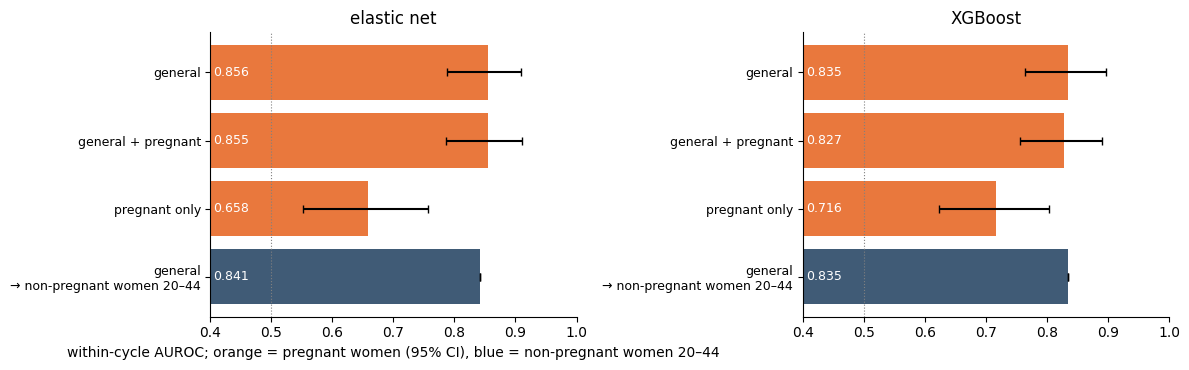

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharex=True)
for ax, model in zip(axes, NAMES.values()):
    m = met[met.model == model].iloc[::-1]
    ci = m["95% CI "].fillna("").str.split("–", expand=True).reindex(columns=[0, 1]).apply(pd.to_numeric)
    v = m["within-cycle AUROC"].to_numpy()
    err = np.nan_to_num(np.array([v - ci[0].to_numpy(), ci[1].to_numpy() - v]))
    colors = ["#405B76" if "non-pregnant" in t else "#E9783D" for t in m.training]
    ax.barh(range(len(m)), v, xerr=err, color=colors, capsize=3)
    ax.set_yticks(range(len(m)), [t.replace(", tested on ", "\n→ ") for t in m.training], fontsize=9)
    for i, x in enumerate(v):
        ax.text(0.405, i, f"{x:.3f}", va="center", color="white", fontsize=9)
    ax.set_xlim(0.4, 1.0)
    ax.axvline(0.5, color="grey", lw=0.8, ls=":")
    ax.set_title(model)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_xlabel("within-cycle AUROC; orange = pregnant women (95% CI), blue = non-pregnant women 20–44")
plots.show()

The pregnant-only models, per test cycle (from `run_loco`): chosen hyper-parameters and AUROC. The cycles after 2005–06 have 2–8 positives, so their AUROC is only shown to make the noise visible.

In [6]:
print((OUT / "pregnant_only" / "report.txt").read_text())

LOCO within pregnant women only, 317 features

mean (sd) over test cycles, each cycle weighted equally:
         auroc        auroc_weighted         auprc         brier       
          mean    std           mean    std   mean    std   mean    std
model                                                                  
logreg   0.723  0.077          0.782  0.100  0.259  0.158  0.184  0.053
xgboost  0.653  0.207          0.697  0.179  0.266  0.215  0.152  0.049

AUROC of all out-of-cycle predictions pooled:
model
logreg     0.663
xgboost    0.641

per test cycle:
  model test_cycle  auroc  auroc_weighted  auprc  brier   n  prevalence  minutes
 logreg    2005-06  0.642           0.679  0.154  0.233 309       0.074      0.2
xgboost    2005-06  0.713           0.705  0.197  0.220 309       0.074      0.2
 logreg    2007-08  0.643           0.779  0.120  0.163  53       0.075      0.2
xgboost    2007-08  0.439           0.522  0.083  0.141  53       0.075      0.2
 logreg    2009-10  0.734  

## Conclusions

- **The general model works for pregnant women as well as for other women of the same age.** Within-cycle AUROC on the 630 pregnant women: 0.856 (95% CI 0.788–0.909) for elastic net and 0.835 (0.764–0.896) for XGBoost. On non-pregnant women aged 20–44 the same models reach 0.841 and 0.835. The model never saw a pregnant woman in training.
- **A model trained on pregnant women only is much worse:** 0.658 (0.552–0.756) and 0.716 (0.623–0.804). The general model is better by +0.198 (95% CI +0.113 to +0.296) for elastic net and +0.119 (+0.047 to +0.194) for XGBoost, on the same women. Pooled AUROC says the same (0.848 / 0.826 against 0.663 / 0.641).
- **The reason is the number of people, not the group.** The pregnant-only models train on 320–585 women with 28–49 positives and 317 features. Step 13 showed that the general model already loses 0.04 at 2,870 training people; here there are five to nine times fewer. Their AUROC per test cycle ranges from 0.35 to 0.88, which is noise.
- **Adding the pregnant women to the general training data changes nothing:** +0.000 / −0.007 within-cycle, intervals include 0. About 550 women next to 28,700 people cannot move the model.
- **Limits:** 51 positives in total, so the intervals are about ±0.06; half of the women are from 2005–06; there is no gestational age, so early and late pregnancy cannot be told apart; and PHQ-9 items such as tiredness, sleep and appetite also change with pregnancy itself, which this analysis does not address.
- **In short:** in NHANES a separate model for pregnant women is not supported by the data. What predicts PHQ-9 ≥ 10 in the general population also predicts it in pregnant women, and the general model is the better choice for them.